# Step 3: Feature Extraction - YOGA Chatbot

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Extract TF-IDF features from preprocessed text

**Date**: 2025-12-01

**Input**: Preprocessed text from Step 2

**Feature Extraction Steps**:
1. Load preprocessed data
2. Build TF-IDF vectorizer
3. Transform text to TF-IDF vectors
4. Encode labels
5. Save features for modeling

**Method**: TF-IDF (Term Frequency-Inverse Document Frequency)

## 1. Import Libraries

In [92]:
import numpy as np
import pandas as pd
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
from datetime import datetime

# Sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seed
np.random.seed(42)

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load Preprocessed Data

In [93]:
print("=" * 80)
print("LOADING PREPROCESSED DATA")
print("=" * 80)

df = pd.read_csv('../data/preprocessed/preprocessed_text.csv')

print(f"Loaded preprocessed data: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst 3 rows:")
print(df.head(3))

# Load preprocessing info
with open('../data/preprocessed/preprocessing_info.json', 'r', encoding='utf-8') as f:
    preprocess_info = json.load(f)

print(f"\nPreprocessing Info:")
print(f"  Total samples: {preprocess_info['total_patterns']}")
print(f"  Number of classes: {preprocess_info['unique_labels']}")
print(f"  Vocabulary size: {preprocess_info['stemmed_vocab_size']}")

LOADING PREPROCESSED DATA
Loaded preprocessed data: (2247, 3)

Columns: ['pattern', 'processed_text', 'label']

First 3 rows:
  pattern processed_text     label
0    halo           halo  greeting
1     hai            hai  greeting
2     hey            hey  greeting

Preprocessing Info:
  Total samples: 2247
  Number of classes: 88
  Vocabulary size: 286


## 3. Prepare Data for TF-IDF

In [94]:
print("=" * 80)
print("PREPARE DATA FOR TF-IDF")
print("=" * 80)

# Use processed_text (stemmed tokens)
texts = df['processed_text'].values
labels = df['label'].values

print(f"Total texts: {len(texts)}")
print(f"Total labels: {len(labels)}")
print(f"Unique classes: {len(np.unique(labels))}")

print(f"\nSample texts:")
for i in range(3):
    print(f"  {labels[i]}: {texts[i]}")

PREPARE DATA FOR TF-IDF
Total texts: 2247
Total labels: 2247
Unique classes: 88

Sample texts:
  greeting: halo
  greeting: hai
  greeting: hey


## 4. Build TF-IDF Vectorizer

In [95]:
print("=" * 80)
print("BUILD TF-IDF VECTORIZER")
print("=" * 80)

# TF-IDF parameters
max_features = 1000
ngram_range = (1, 2)
min_df = 2
max_df = 0.8

print(f"TF-IDF Parameters:")
print(f"  max_features: {max_features}")
print(f"  ngram_range: {ngram_range}")
print(f"  min_df: {min_df}")
print(f"  max_df: {max_df}")

# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=max_features,
    ngram_range=ngram_range,
    min_df=min_df,
    max_df=max_df,
    token_pattern=r'\b\w+\b'
)

print("\nTF-IDF Vectorizer created")

BUILD TF-IDF VECTORIZER
TF-IDF Parameters:
  max_features: 1000
  ngram_range: (1, 2)
  min_df: 2
  max_df: 0.8

TF-IDF Vectorizer created


## 5. Fit and Transform

In [96]:
print("=" * 80)
print("FIT AND TRANSFORM TF-IDF")
print("=" * 80)

# Fit and transform
X_tfidf = tfidf_vectorizer.fit_transform(texts)

print(f"TF-IDF matrix shape: {X_tfidf.shape}")
print(f"  Samples: {X_tfidf.shape[0]}")
print(f"  Features: {X_tfidf.shape[1]}")

# Get vocabulary
vocab = tfidf_vectorizer.get_feature_names_out()
print(f"\nVocabulary size: {len(vocab)}")
print(f"\nFirst 20 features: {list(vocab[:20])}")

# Convert to dense array for saving
X_tfidf_dense = X_tfidf.toarray()
print(f"\nConverted to dense array: {X_tfidf_dense.shape}")

# Statistics
print(f"\nTF-IDF Statistics:")
print(f"  Min: {X_tfidf_dense.min():.6f}")
print(f"  Max: {X_tfidf_dense.max():.6f}")
print(f"  Mean: {X_tfidf_dense.mean():.6f}")
print(f"  Std: {X_tfidf_dense.std():.6f}")
print(f"  Sparsity: {(X_tfidf_dense == 0).sum() / X_tfidf_dense.size * 100:.2f}%")

FIT AND TRANSFORM TF-IDF
TF-IDF matrix shape: (2247, 1000)
  Samples: 2247
  Features: 1000

Vocabulary size: 1000

First 20 features: ['ada', 'ada apa', 'ada bukit', 'ada cafe', 'ada destinasi', 'ada di', 'ada ga', 'ada hidden', 'ada ide', 'ada lokasi', 'ada museum', 'ada objek', 'ada pantai', 'ada saran', 'ada spot', 'ada taman', 'ada tempat', 'ada wisata', 'afternoon', 'afternoon yoga']

Converted to dense array: (2247, 1000)

TF-IDF Statistics:
  Min: 0.000000
  Max: 1.000000
  Mean: 0.002435
  Std: 0.031423
  Sparsity: 99.30%


## 6. Encode Labels

In [97]:
print("=" * 80)
print("ENCODE LABELS")
print("=" * 80)

# Encode labels to integers
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

print(f"Label encoder fitted")
print(f"  Classes: {len(label_encoder.classes_)}")
print(f"  y shape: {y.shape}")

print(f"\nClass mapping (first 10):")
for i, class_name in enumerate(label_encoder.classes_[:10]):
    print(f"  {i}: {class_name}")

# Class distribution
unique, counts = np.unique(y, return_counts=True)
print(f"\nClass distribution:")
print(f"  Min samples per class: {counts.min()}")
print(f"  Max samples per class: {counts.max()}")
print(f"  Mean samples per class: {counts.mean():.2f}")
print(f"  Median samples per class: {np.median(counts):.2f}")

ENCODE LABELS
Label encoder fitted
  Classes: 88
  y shape: (2247,)

Class mapping (first 10):
  0: goodbye
  1: greeting
  2: kabupaten_bantul
  3: kabupaten_gunungkidul
  4: kabupaten_kulonprogo
  5: kabupaten_sleman
  6: kecamatan_bambanglipuro
  7: kecamatan_banguntapan
  8: kecamatan_berbah
  9: kecamatan_cangkringan

Class distribution:
  Min samples per class: 25
  Max samples per class: 36
  Mean samples per class: 25.53
  Median samples per class: 25.00


## 6b. Build Greeting-Optimized TF-IDF

In [98]:
print("=" * 80)
print("BUILD GREETING-OPTIMIZED TF-IDF")
print("=" * 80)

# Greeting TF-IDF parameters (optimized for short greeting texts)
max_features_greeting = 500
ngram_range_greeting = (1, 2)
min_df_greeting = 1  # Keep rare terms for greeting detection
max_df_greeting = 0.9

print(f"\nGreeting TF-IDF Parameters:")
print(f"  max_features: {max_features_greeting}")
print(f"  ngram_range: {ngram_range_greeting}")
print(f"  min_df: {min_df_greeting}")
print(f"  max_df: {max_df_greeting}")

# Create greeting TF-IDF vectorizer
tfidf_greeting = TfidfVectorizer(
    max_features=max_features_greeting,
    ngram_range=ngram_range_greeting,
    min_df=min_df_greeting,
    max_df=max_df_greeting,
    token_pattern=r'\b\w+\b'
)

# Fit and transform with same texts
X_tfidf_greeting = tfidf_greeting.fit_transform(texts)

print(f"\nGreeting TF-IDF matrix shape: {X_tfidf_greeting.shape}")
print(f"  Samples: {X_tfidf_greeting.shape[0]}")
print(f"  Features: {X_tfidf_greeting.shape[1]}")

# Get vocabulary
vocab_greeting = tfidf_greeting.get_feature_names_out()
print(f"\nGreeting vocabulary size: {len(vocab_greeting)}")
print(f"First 20 greeting features: {list(vocab_greeting[:20])}")

# Convert to dense array
X_tfidf_greeting_dense = X_tfidf_greeting.toarray()
print(f"\nConverted to dense array: {X_tfidf_greeting_dense.shape}")

print(f"\nGreeting TF-IDF Statistics:")
print(f"  Min: {X_tfidf_greeting_dense.min():.6f}")
print(f"  Max: {X_tfidf_greeting_dense.max():.6f}")
print(f"  Mean: {X_tfidf_greeting_dense.mean():.6f}")
print(f"  Sparsity: {(X_tfidf_greeting_dense == 0).sum() / X_tfidf_greeting_dense.size * 100:.2f}%")

BUILD GREETING-OPTIMIZED TF-IDF

Greeting TF-IDF Parameters:
  max_features: 500
  ngram_range: (1, 2)
  min_df: 1
  max_df: 0.9

Greeting TF-IDF matrix shape: (2247, 500)
  Samples: 2247
  Features: 500

Greeting vocabulary size: 500
First 20 greeting features: ['ada', 'ada apa', 'ada bukit', 'ada cafe', 'ada destinasi', 'ada hidden', 'ada ide', 'ada museum', 'ada pantai', 'ada spot', 'ada tempat', 'ada wisata', 'afternoon', 'aja', 'aja kalo', 'aja sih', 'aku', 'aku butuh', 'aku spot', 'alam']

Converted to dense array: (2247, 500)

Greeting TF-IDF Statistics:
  Min: 0.000000
  Max: 1.000000
  Mean: 0.004661
  Sparsity: 98.72%


## 7. Visualizations

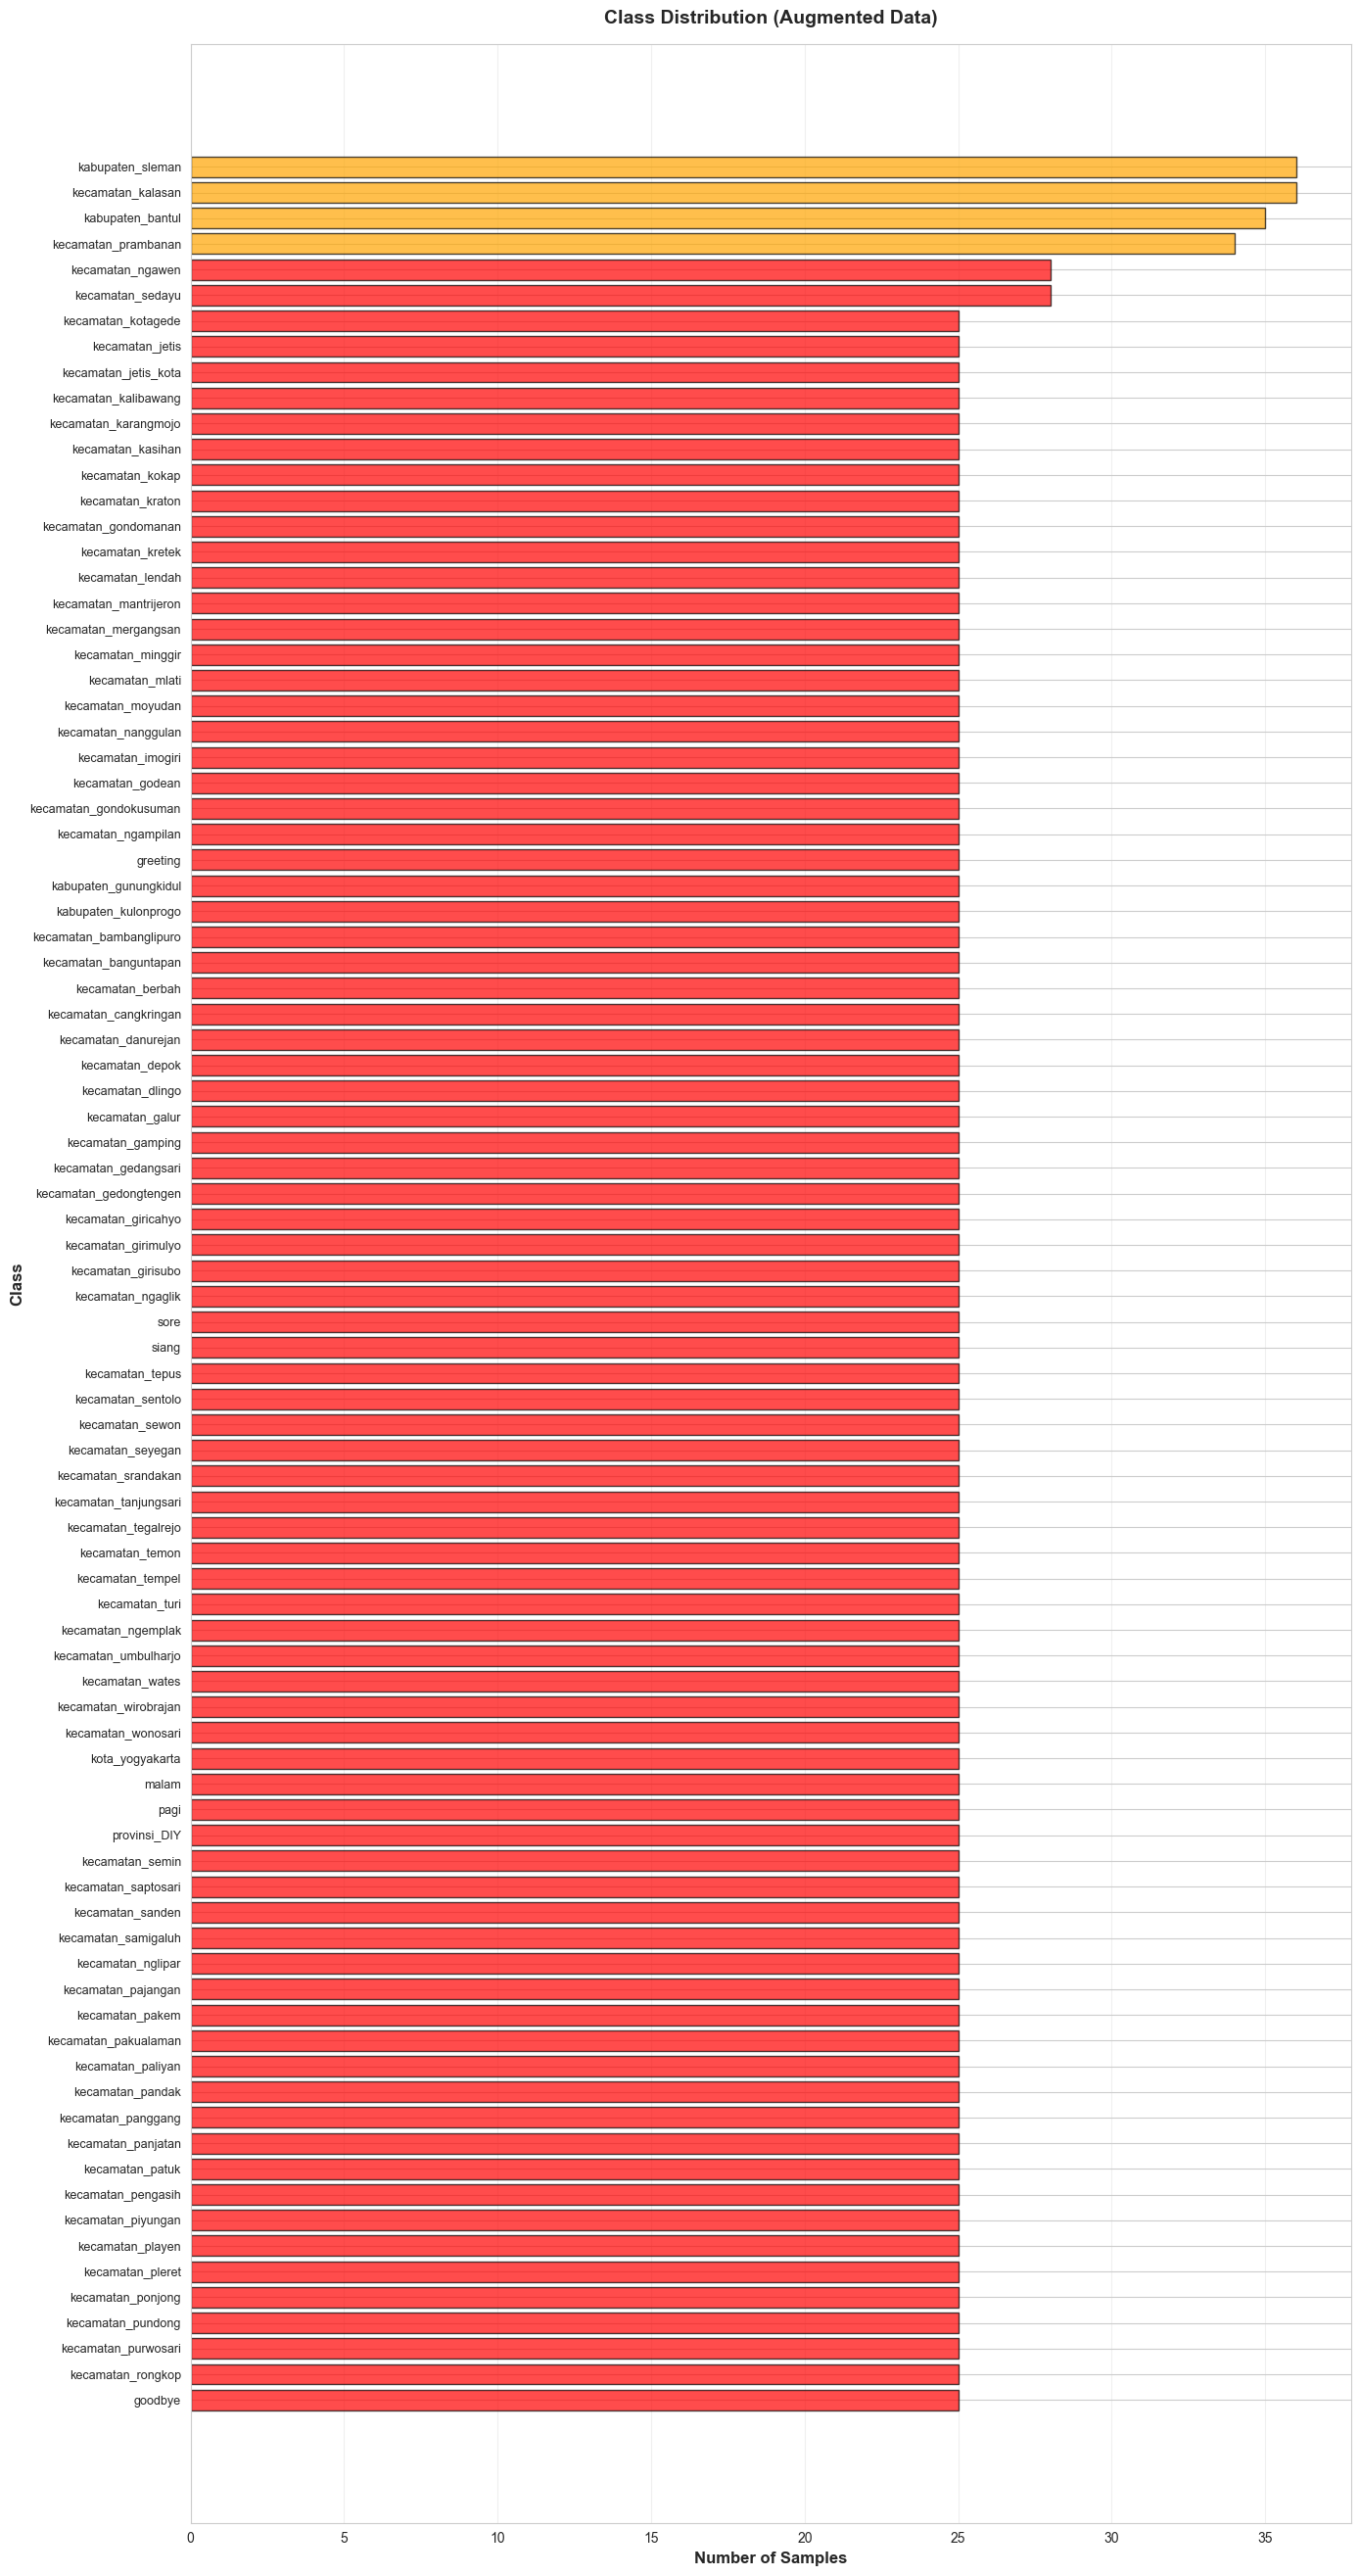

Class distribution visualization saved


In [100]:
# Class distribution bar chart
class_counts = pd.DataFrame({
    'Class': label_encoder.classes_,
    'Count': [np.sum(y == i) for i in range(len(label_encoder.classes_))]
}).sort_values('Count', ascending=True)

plt.figure(figsize=(14, max(10, len(class_counts) * 0.3)))
colors = ['green' if c >= 50 else 'orange' if c >= 30 else 'red' for c in class_counts['Count']]
plt.barh(range(len(class_counts)), class_counts['Count'], color=colors, alpha=0.7, edgecolor='black')
plt.yticks(range(len(class_counts)), class_counts['Class'], fontsize=9)
plt.xlabel('Number of Samples', fontsize=12, fontweight='bold')
plt.ylabel('Class', fontsize=12, fontweight='bold')
plt.title('Class Distribution (Augmented Data)', fontsize=14, fontweight='bold', pad=15)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Class distribution visualization saved")

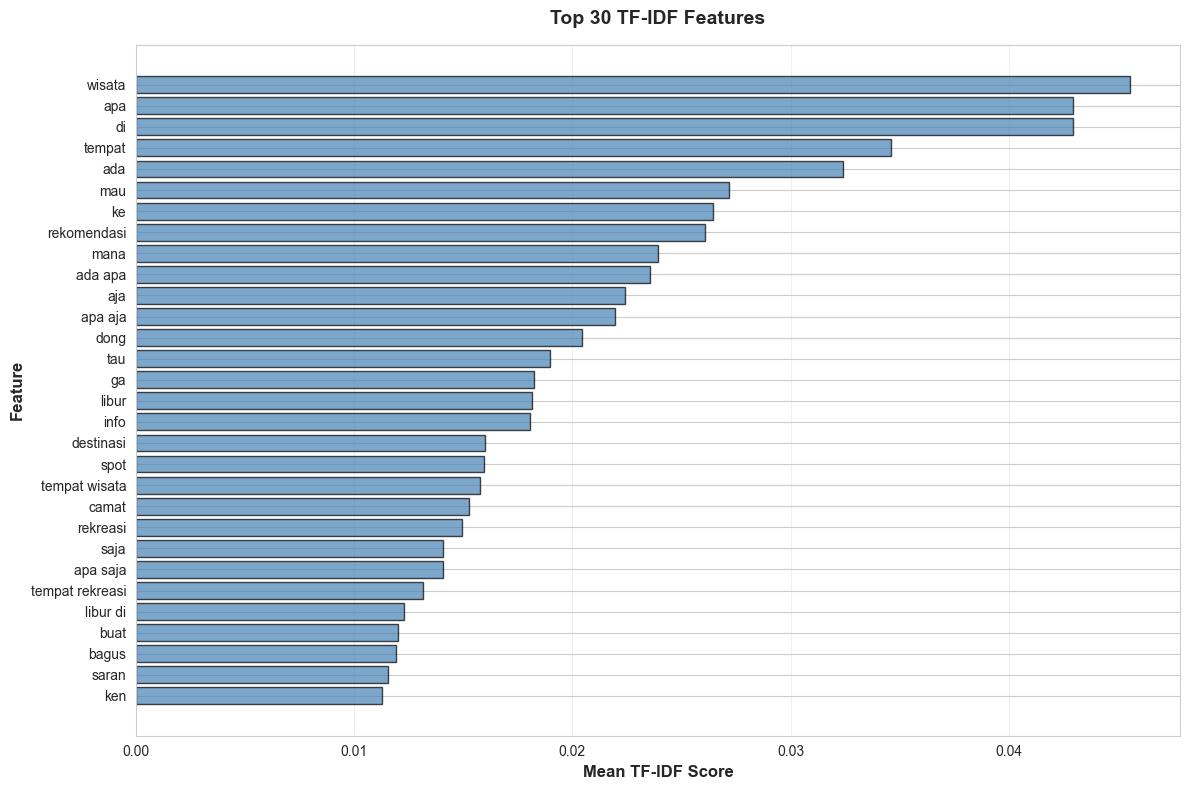

Top TF-IDF features visualization saved


In [102]:
# Top TF-IDF features
feature_importance = X_tfidf_dense.mean(axis=0)
top_indices = np.argsort(feature_importance)[-30:]
top_features = vocab[top_indices]
top_scores = feature_importance[top_indices]

plt.figure(figsize=(12, 8))
plt.barh(range(len(top_features)), top_scores, color='steelblue', alpha=0.7, edgecolor='black')
plt.yticks(range(len(top_features)), top_features, fontsize=10)
plt.xlabel('Mean TF-IDF Score', fontsize=12, fontweight='bold')
plt.ylabel('Feature', fontsize=12, fontweight='bold')
plt.title('Top 30 TF-IDF Features', fontsize=14, fontweight='bold', pad=15)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Top TF-IDF features visualization saved")

## 8. Save Features

In [103]:
print("=" * 80)
print("SAVING FEATURES")
print("=" * 80)

# Create output directory
os.makedirs('../data/features', exist_ok=True)

# Save main TF-IDF matrix
np.save('../data/features/X_tfidf.npy', X_tfidf_dense)
print("Saved: X_tfidf.npy")

# Save greeting TF-IDF matrix
np.save('../data/features/X_tfidf_greeting.npy', X_tfidf_greeting_dense)
print("Saved: X_tfidf_greeting.npy")

# Save labels
np.save('../data/features/y.npy', y)
print("Saved: y.npy")

# Save main TF-IDF vectorizer
with open('../data/features/tfidf_vectorizer.pickle', 'wb') as f:
    pickle.dump(tfidf_vectorizer, f)
print("Saved: tfidf_vectorizer.pickle")

# Save greeting TF-IDF vectorizer
with open('../data/features/tfidf_greeting.pickle', 'wb') as f:
    pickle.dump(tfidf_greeting, f)
print("Saved: tfidf_greeting.pickle")

# Save label encoder
with open('../data/features/label_encoder.pickle', 'wb') as f:
    pickle.dump(label_encoder, f)
print("Saved: label_encoder.pickle")

# Save feature extraction info
feature_info = {
    'method': 'TF-IDF',
    'main_tfidf': {
        'max_features': max_features,
        'ngram_range': ngram_range,
        'min_df': min_df,
        'max_df': max_df,
        'vocab_size': len(vocab),
        'features': X_tfidf_dense.shape[1]
    },
    'greeting_tfidf': {
        'max_features': max_features_greeting,
        'ngram_range': ngram_range_greeting,
        'min_df': min_df_greeting,
        'max_df': max_df_greeting,
        'vocab_size': len(vocab_greeting),
        'features': X_tfidf_greeting_dense.shape[1]
    },
    'tfidf_features': X_tfidf_dense.shape[1],
    'total_samples': X_tfidf_dense.shape[0],
    'num_classes': len(label_encoder.classes_),
    'sparsity': float((X_tfidf_dense == 0).sum() / X_tfidf_dense.size),
    'class_names': label_encoder.classes_.tolist(),
    'tfidf_stats': {
        'min': float(X_tfidf_dense.min()),
        'max': float(X_tfidf_dense.max()),
        'mean': float(X_tfidf_dense.mean()),
        'std': float(X_tfidf_dense.std())
    },
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

with open('../data/features/feature_extraction_info.json', 'w') as f:
    json.dump(feature_info, f, indent=2)
print("Saved: feature_extraction_info.json")

print("\nAll files saved successfully")

SAVING FEATURES
Saved: X_tfidf.npy
Saved: X_tfidf_greeting.npy
Saved: y.npy
Saved: tfidf_vectorizer.pickle
Saved: tfidf_greeting.pickle
Saved: label_encoder.pickle
Saved: feature_extraction_info.json

All files saved successfully


## 9. Summary

In [ ]:
print("=" * 80)
print("FEATURE EXTRACTION SUMMARY - YOGA CHATBOT")
print("=" * 80)

print("\nInput:")
print(f"  Source: preprocessed_text.csv")
print(f"  Total samples: {len(texts)}")
print(f"  Number of classes: {len(label_encoder.classes_)}")

print("\nMain TF-IDF Configuration:")
print(f"  Max features: {max_features}")
print(f"  N-gram range: {ngram_range}")
print(f"  Min document frequency: {min_df}")
print(f"  Max document frequency: {max_df}")
print(f"  Output shape: {X_tfidf_dense.shape}")

print("\nGreeting TF-IDF Configuration:")
print(f"  Max features: {max_features_greeting}")
print(f"  N-gram range: {ngram_range_greeting}")
print(f"  Min document frequency: {min_df_greeting}")
print(f"  Max document frequency: {max_df_greeting}")
print(f"  Output shape: {X_tfidf_greeting_dense.shape}")

print("\nSaved Files:")
print(f"  - X_tfidf.npy (main features for 88-class SVM)")
print(f"  - X_tfidf_greeting.npy (greeting features for binary detector)")
print(f"  - y.npy (labels)")
print(f"  - tfidf_vectorizer.pickle (main vectorizer)")
print(f"  - tfidf_greeting.pickle (greeting vectorizer)")
print(f"  - label_encoder.pickle (for deployment)")
print(f"  - feature_extraction_info.json (metadata)")

print("\nFeatures ready for hybrid modeling")
print("=" * 80)